# ShopSmart Retail: Exploratory Data Analysis (Week 1)
**Track:** Data Science | **Author:** *Charity Nduati* | **Client:** ShopSmart Retail Ltd.

**Sections in this notebook:** 1 Setup and load, 2 Data audit, 3 Cleaning, 4 Merge and KPIs.
Later parts (visuals, correlation, feature engineering, business questions) build on `master` created here.

## 1. Setup and load data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
try:
    import missingno as msno
except ImportError:   # optional: run `pip install missingno` for the original chart
    msno = None
    print("missingno is not installed, so a simple fallback chart is used. Install it with: pip install missingno")

def plot_missing(df, ax, fontsize=7):
    """Missing-value bar chart (missingno if available, otherwise % complete per column)."""
    if msno is not None:
        msno.bar(df, ax=ax, fontsize=fontsize)
    else:
        (df.notna().mean() * 100).plot.bar(ax=ax, color="#555555")
        ax.set_ylim(0, 105); ax.set_ylabel("% complete"); ax.tick_params(labelsize=fontsize)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

import os

# ---- Locate the CSV files automatically ------------------------------------
# If your CSVs are somewhere unusual, set the folder here, e.g. DATA_DIR = r"C:\Users\HomePC\Downloads\ShopSmart"
DATA_DIR = None

KEYS = ["customers", "products", "orders", "stores", "returns", "employees", "suppliers", "inventory"]

def find_file(folder, key):
    """Find e.g. ShopSmart_Orders.csv / ALA_ShopSmart_Customers.csv / orders.csv (ignores Order_Items)."""
    hits = [f for f in os.listdir(folder) if f.lower().endswith(".csv") and key in f.lower() and "item" not in f.lower()]
    return hits[0] if hits else None

candidates = [DATA_DIR] if DATA_DIR else ["data", ".", "..", os.path.join("..", "data"),
                                          os.path.join(os.path.expanduser("~"), "Downloads")]
FILES = None
for folder in candidates:
    if folder and os.path.isdir(folder) and all(find_file(folder, k) for k in KEYS):
        DATA_DIR, FILES = folder, {k: find_file(folder, k) for k in KEYS}
        break
if FILES is None:
    raise FileNotFoundError(
        "Could not find the ShopSmart CSV files.\n"
        f"Current folder: {os.getcwd()}\n"
        "Fix: put the 8 CSVs in a folder called 'data' next to this notebook, "
        "or set DATA_DIR above to the folder that contains them.")
print("Using data folder:", os.path.abspath(DATA_DIR))
raw = {k: pd.read_csv(os.path.join(DATA_DIR, f)) for k, f in FILES.items()}
{k: v.shape for k, v in raw.items()}

Using data folder: c:\Users\HomePC\Documents\ShopSmart retail analytics data science project


{'customers': (5000, 11),
 'products': (500, 7),
 'orders': (50000, 12),
 'stores': (25, 6),
 'returns': (2500, 5),
 'employees': (125, 6),
 'suppliers': (489, 6),
 'inventory': (500, 6)}

In [2]:
# head / tail / shape / columns / dtypes / missing values for every table
for name, df in raw.items():
    print(f"\n{'='*20} {name.upper()} {'='*20}")
    display(df.head(3)); display(df.tail(3))
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print(df.dtypes.to_string())
    print("Missing values:", int(df.isna().sum().sum()))


==================== CUSTOMERS ====================


,Customer_ID,First_Name,Last_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
0,CUST00001,Michelle,Russell,Male,65,elizabethfox@example.net,(701)981-5738x907,Abuja,Abuja,10/9/2023,Bronze
1,CUST00002,Sarah,Yu,Male,65,tfleming@example.com,6314323702,Kano,Kano,4/15/2023,Gold
2,CUST00003,Elizabeth,Adkins,Male,55,petertaylor@example.com,001-454-212-5805x0434,Asaba,Delta,3/8/2024,Bronze


,Customer_ID,First_Name,Last_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
4997,CUST04998,Rebecca,Green,Male,66,jennifer26@example.com,477.407.6109x1571,Awka,Anambra,9/14/2024,Bronze
4998,CUST04999,Kathleen,Richards,Female,55,xmcdaniel@example.net,422.953.9359x7224,Port Harcourt,Rivers,4/6/2024,Silver
4999,CUST05000,Colleen,Anderson,Female,44,mendozamichelle@example.com,(278)379-9765x355,Kano,Kano,9/28/2023,Bronze


Shape: (5000, 11)
Columns: ['Customer_ID', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Email', 'Phone', 'City', 'State', 'Registration_Date', 'Customer_Segment']
Customer_ID          object
First_Name           object
Last_Name            object
Gender               object
Age                   int64
Email                object
Phone                object
City                 object
State                object
Registration_Date    object
Customer_Segment     object
Missing values: 0

==================== PRODUCTS ====================


,Product_ID,Product_Name,Category,Sub_Category,Brand,Cost_Price,Selling_Price
0,PROD0001,Beauty Item 1,Beauty,General,Zuniga PLC,44803,75526.21
1,PROD0002,Beauty Item 2,Beauty,General,Olson-Rosales,11728,14100.26
2,PROD0003,Electronics Item 3,Electronics,General,"Mosley, Watson and Middleton",39383,52368.82


...

,Supplier_ID,Supplier_Name,Email,Phone,City,Country
486,SUP487,Collins-Stewart Supplies,schwartzcourtney@gomez.info,579-484-4995x45,Raymondhaven,USA
487,SUP488,"Johnson, Brown and Strickland Supplies",manningmargaret@schwartz.com,(362)284-7191x1,East Adamton,China
488,SUP489,Lucas and Sons Supplies,normanbrian@thompson.org,577.337.0263x94,Kimport,China


Shape: (489, 6)
Columns: ['Supplier_ID', 'Supplier_Name', 'Email', 'Phone', 'City', 'Country']
Supplier_ID      object
Supplier_Name    object
Email            object
Phone            object
City             object
Country          object
Missing values: 0

==================== INVENTORY ====================


,Inventory_ID,Product_ID,Store_ID,Stock_On_Hand,Reorder_Level,Last_Restock_Date
0,INV00001,PROD0001,STR002,94,26,8/16/2026
1,INV00002,PROD0002,STR021,338,17,8/27/2026
2,INV00003,PROD0003,STR007,178,27,9/26/2026


,Inventory_ID,Product_ID,Store_ID,Stock_On_Hand,Reorder_Level,Last_Restock_Date
497,INV00498,PROD0498,STR001,45,6,8/19/2026
498,INV00499,PROD0499,STR020,99,16,9/23/2026
499,INV00500,PROD0500,STR020,424,23,9/2/2026


Shape: (500, 6)
Columns: ['Inventory_ID', 'Product_ID', 'Store_ID', 'Stock_On_Hand', 'Reorder_Level', 'Last_Restock_Date']
Inventory_ID         object
Product_ID           object
Store_ID             object
Stock_On_Hand         int64
Reorder_Level         int64
Last_Restock_Date    object
Missing values: 0


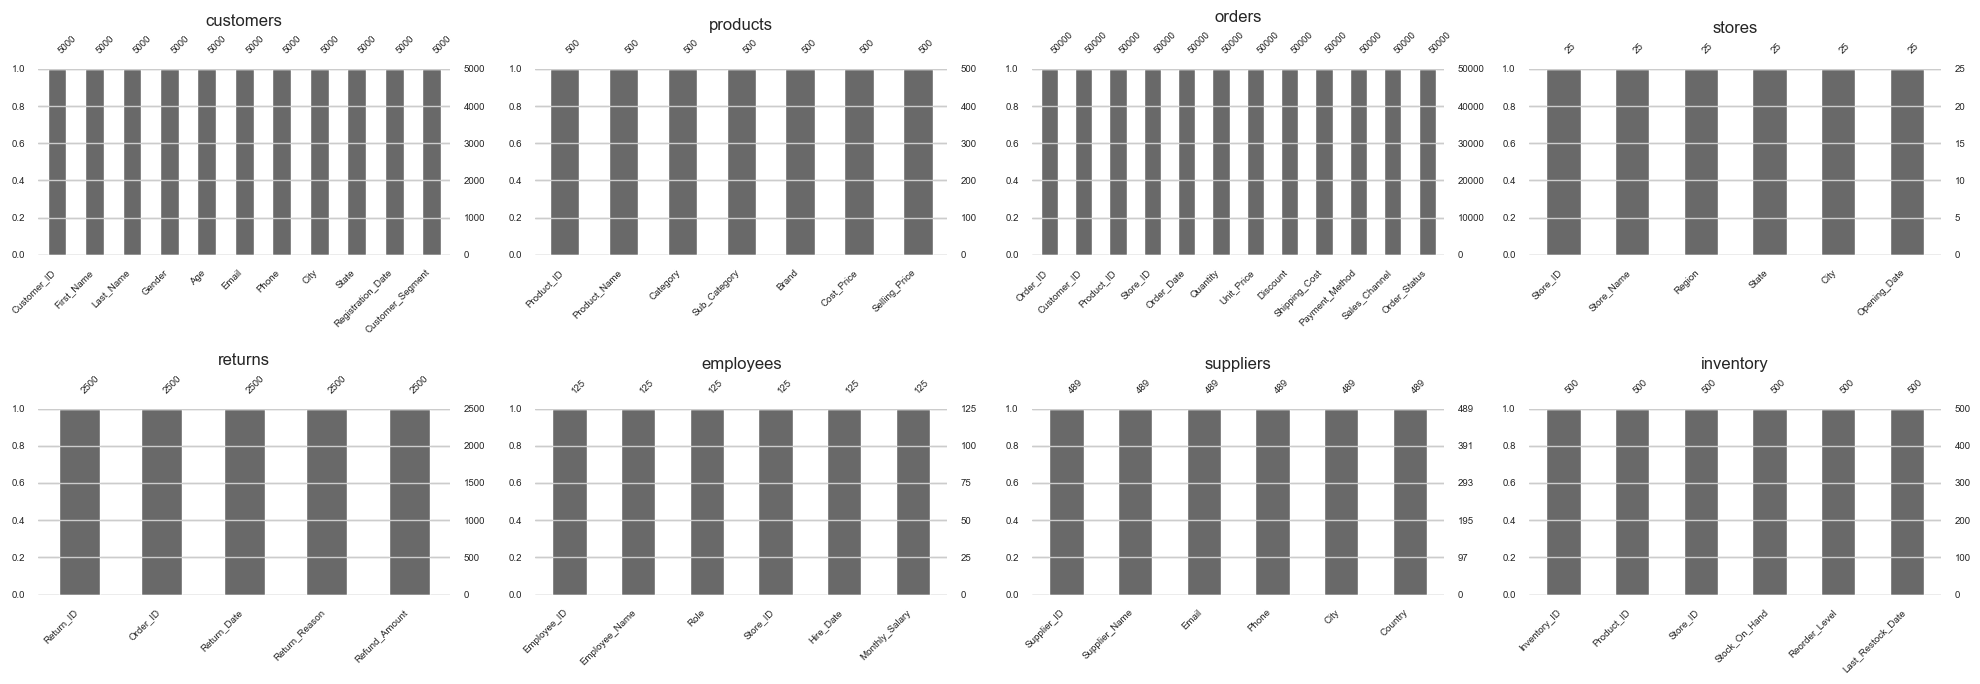

In [3]:
# Visual missing-value check (one panel per table). A fully dark bar = no gaps.
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for ax, (name, df) in zip(axes.ravel(), raw.items()):
    plot_missing(df, ax); ax.set_title(name)
plt.tight_layout(); os.makedirs("Visualizations", exist_ok=True)
plt.savefig("Visualizations/00_missing_values.png", dpi=150, bbox_inches="tight"); plt.show()

In [4]:
# The brief also lists Order_Items.csv and a Data Dictionary. Load them if they are in the data folder.
for f in os.listdir(DATA_DIR):
    low = f.lower()
    if low.endswith(".csv") and "item" in low:
        raw["order_items"] = pd.read_csv(os.path.join(DATA_DIR, f)); print("Loaded", f, raw["order_items"].shape)
    if low.endswith(".xlsx") and "dictionary" in low:
        data_dictionary = pd.read_excel(os.path.join(DATA_DIR, f), sheet_name=None); print("Loaded", f, list(data_dictionary))
print("Tables loaded:", list(raw))

Loaded ShopSmart_Order_Items.csv (50000, 7)
Tables loaded: ['customers', 'products', 'orders', 'stores', 'returns', 'employees', 'suppliers', 'inventory', 'order_items']


**Note on files:** all 8 supplied tables are loaded and used (Customers, Products, Orders, Stores, Returns, Employees, Suppliers, Inventory).
`Order_Items.csv` and the Data Dictionary were not in the shared files. `Orders.csv` is already at line level (one product per `Order_ID`), so Order_Items is not needed. The cell above loads them automatically if you place them in `data/`.

## 2. Data audit (before touching anything)

In [5]:
# Keys: is each primary key unique, and do all foreign keys point to a real parent row?
pk = {"customers":"Customer_ID","products":"Product_ID","orders":"Order_ID","stores":"Store_ID",
      "returns":"Return_ID","employees":"Employee_ID","suppliers":"Supplier_ID","inventory":"Inventory_ID"}
print("Primary keys unique?", {t: raw[t][c].is_unique for t, c in pk.items()})

fks = [("orders","Customer_ID","customers"),("orders","Product_ID","products"),("orders","Store_ID","stores"),
       ("returns","Order_ID","orders"),("inventory","Product_ID","products"),("inventory","Store_ID","stores"),
       ("employees","Store_ID","stores")]
for child, col, parent in fks:
    orphans = (~raw[child][col].isin(raw[parent][pk[parent]])).sum()
    print(f"{child}.{col} -> {parent}: {orphans} orphan rows")

Primary keys unique? {'customers': True, 'products': True, 'orders': True, 'stores': True, 'returns': True, 'employees': True, 'suppliers': True, 'inventory': True}
orders.Customer_ID -> customers: 0 orphan rows
orders.Product_ID -> products: 0 orphan rows
orders.Store_ID -> stores: 0 orphan rows
returns.Order_ID -> orders: 0 orphan rows
inventory.Product_ID -> products: 0 orphan rows
inventory.Store_ID -> stores: 0 orphan rows
employees.Store_ID -> stores: 0 orphan rows


In [6]:
# Spot-check suspicious things
o, r, s, p = raw["orders"], raw["returns"], raw["stores"], raw["products"]
print("Duplicate full rows per table:", {k: int(v.duplicated().sum()) for k, v in raw.items()})
print("\nOrder_Status:\n", o.Order_Status.value_counts())
print("\nReturns pointing at the same order more than once:", r.Order_ID.duplicated().sum())
print("Returns on non-completed orders:", r.merge(o, on="Order_ID").query("Order_Status != 'Completed'").shape[0], "of", len(r))
print("\nStore names that repeat:\n", s.Store_Name.value_counts().loc[lambda x: x > 1])
print("\nRegion per State (should be 1 each if clean):\n", s.groupby("State").Region.nunique())
m = o.merge(p, on="Product_ID")
print("\nOrder Unit_Price equals catalogue Selling_Price in", round((abs(m.Unit_Price-m.Selling_Price) < 1).mean()*100, 1), "% of orders")

Duplicate full rows per table: {'customers': 0, 'products': 0, 'orders': 0, 'stores': 0, 'returns': 0, 'employees': 0, 'suppliers': 0, 'inventory': 0, 'order_items': 0}

Order_Status:
 Order_Status
Cancelled    16861
Pending      16610
Completed    16529
Name: count, dtype: int64

Returns pointing at the same order more than once: 58
Returns on non-completed orders: 1685 of 2500

Store names that repeat:
 Store_Name
ShopSmart Abuja            4
ShopSmart Lagos            4
ShopSmart Ibadan           4
ShopSmart Asaba            3
ShopSmart Kaduna           3
ShopSmart Port Harcourt    2
ShopSmart Abeokuta         2
Name: count, dtype: int64

Region per State (should be 1 each if clean):
 State
Abuja      3
Anambra    1
Delta      3
Enugu      1
Kaduna     3
Kano       1
Lagos      4
Ogun       2
Oyo        3
Rivers     1
Name: Region, dtype: int64

Order Unit_Price equals catalogue Selling_Price in 0.0 % of orders


### Audit findings (these drive the cleaning decisions)
1. **No missing values and no exact duplicate rows**, and all primary keys are unique. All foreign keys resolve (0 orphans).
2. **Order_Status is split about a third each** between Completed, Pending and Cancelled. Revenue should only count **Completed** orders.
3. **Store names are not unique** (e.g. four "ShopSmart Ibadan"). Always group by `Store_ID`, never by name.
4. **Region does not follow State** (Abuja appears under East, North and South), so Region is unreliable for geography. I use **State** for geographic analysis and report Region with a caveat.
5. **Unit_Price in Orders never equals Products.Selling_Price.** I treat the order's own `Unit_Price` as the transaction price.
6. **58 returns repeat the same order** (de-duplicated in section 3). **1,685 of the 2,500 returns (67%) are on Pending or Cancelled orders**, which is logically impossible, so treat it as a data-quality finding and report it.
7. **About 5,000 orders are dated before the customer's registration date.** Flagged, not deleted; mention it in the report.

## 3. Cleaning

In [7]:
clean = {k: v.copy() for k, v in raw.items()}
log = []   # cleaning log, exported at the end as evidence for the report

def note(table, step, detail):
    log.append({"table": table, "step": step, "detail": detail}); print(f"[{table}] {step}: {detail}")

def to_snake(df):
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]; return df

def clean_dates(df, col, table):
    before = df[col].isna().sum()
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y", errors="coerce")
    note(table, "dates", f"{col} -> datetime ({df[col].isna().sum() - before} unparseable)"); return df

def clean_text(df, cols, table):
    for c in cols: df[c] = df[c].astype(str).str.strip().str.title()
    note(table, "text", f"stripped/title-cased {cols}"); return df

In [8]:
# Duplicates and snake_case for every table
for name, df in clean.items():
    n = df.duplicated().sum(); df.drop_duplicates(inplace=True)
    note(name, "duplicates", f"removed {n} exact duplicate rows")
    to_snake(df)

[customers] duplicates: removed 0 exact duplicate rows
[products] duplicates: removed 0 exact duplicate rows
[orders] duplicates: removed 0 exact duplicate rows
[stores] duplicates: removed 0 exact duplicate rows
[returns] duplicates: removed 0 exact duplicate rows
[employees] duplicates: removed 0 exact duplicate rows
[suppliers] duplicates: removed 0 exact duplicate rows
[inventory] duplicates: removed 0 exact duplicate rows
[order_items] duplicates: removed 0 exact duplicate rows


In [9]:
# Dates
clean["customers"] = clean_dates(clean["customers"], "registration_date", "customers")
clean["employees"] = clean_dates(clean["employees"], "hire_date", "employees")
clean["inventory"] = clean_dates(clean["inventory"], "last_restock_date", "inventory")
clean["orders"]    = clean_dates(clean["orders"], "order_date", "orders")
clean["returns"]   = clean_dates(clean["returns"], "return_date", "returns")
clean["stores"]    = clean_dates(clean["stores"], "opening_date", "stores")

# Text consistency
clean["customers"] = clean_text(clean["customers"], ["gender","city","state","customer_segment"], "customers")
clean["stores"]    = clean_text(clean["stores"], ["region","state","city"], "stores")
clean["products"]  = clean_text(clean["products"], ["category"], "products")
for t, c in [("customers","gender"),("customers","customer_segment"),("products","category"),("orders","order_status"),("returns","return_reason")]:
    print(t, c, clean[t][c].unique().tolist())

[customers] dates: registration_date -> datetime (0 unparseable)
[employees] dates: hire_date -> datetime (0 unparseable)
[inventory] dates: last_restock_date -> datetime (0 unparseable)
[orders] dates: order_date -> datetime (0 unparseable)
[returns] dates: return_date -> datetime (0 unparseable)
[stores] dates: opening_date -> datetime (0 unparseable)
[customers] text: stripped/title-cased ['gender', 'city', 'state', 'customer_segment']
[stores] text: stripped/title-cased ['region', 'state', 'city']
[products] text: stripped/title-cased ['category']
customers gender ['Male', 'Female']
customers customer_segment ['Bronze', 'Gold', 'Silver']
products category ['Beauty', 'Electronics', 'Home', 'Fashion', 'Groceries']
orders order_status ['Completed', 'Cancelled', 'Pending']
returns return_reason ['Wrong Item', 'Damaged', 'Late Delivery', 'Customer Changed Mind']


In [10]:
# Currency / numeric validation (values are already numeric; this confirms ranges and catches bad values)
checks = {
    "orders":   ["quantity","unit_price","discount","shipping_cost"],
    "products": ["cost_price","selling_price"],
    "returns":  ["refund_amount"],
    "inventory":["stock_on_hand","reorder_level"],
}
for t, cols in checks.items():
    clean[t][cols] = clean[t][cols].apply(pd.to_numeric, errors="coerce")
    print(t, "negatives:", int((clean[t][cols] < 0).sum().sum()), "| nulls:", int(clean[t][cols].isna().sum().sum()))
print("Age range:", clean["customers"].age.min(), "-", clean["customers"].age.max())
print("Orders before customer registered:",
      clean["orders"].merge(clean["customers"], on="customer_id").query("order_date < registration_date").shape[0])

orders negatives: 0 | nulls: 0
products negatives: 0 | nulls: 0
returns negatives: 0 | nulls: 0
inventory negatives: 0 | nulls: 0
Age range: 18 - 70
Orders before customer registered: 5159


In [11]:
# Returns: keep one row per order (a duplicated Order_ID would double-count the return rate)
ret = clean["returns"]
dups = ret.duplicated("order_id", keep="first").sum()
ret = ret.sort_values("return_date").drop_duplicates("order_id", keep="first")
clean["returns"] = ret
note("returns", "duplicate orders", f"kept first return per order_id, dropped {dups} repeats")

[returns] duplicate orders: kept first return per order_id, dropped 58 repeats


In [12]:
# Standardise the supplier contact fields (messy phone formats) and link suppliers to brands.
# In this dataset each supplier name is "<Brand> Supplies", so the brand is the join key.
su = clean["suppliers"]
su["phone_clean"] = su["phone"].astype(str).str.replace(r"[^\d+]", "", regex=True)
su["brand"] = su["supplier_name"].str.replace(r" Supplies$", "", regex=True)
note("suppliers", "brand key", "derived brand from supplier_name (matches products.brand 1:1)")
print("Products with a supplier:", clean["products"].brand.isin(su.brand).mean())

[suppliers] brand key: derived brand from supplier_name (matches products.brand 1:1)
Products with a supplier: 1.0


In [13]:
# Save cleaned tables and the cleaning log
os.makedirs("Cleaned_Data", exist_ok=True)
for name, df in clean.items(): df.to_csv(f"Cleaned_Data/{name}_clean.csv", index=False)
pd.DataFrame(log).to_csv("Cleaned_Data/cleaning_log.csv", index=False)
pd.DataFrame(log)

,table,step,detail
0,customers,duplicates,removed 0 exact duplicate rows
1,products,duplicates,removed 0 exact duplicate rows
2,orders,duplicates,removed 0 exact duplicate rows
3,stores,duplicates,removed 0 exact duplicate rows
4,returns,duplicates,removed 0 exact duplicate rows
5,employees,duplicates,removed 0 exact duplicate rows
6,suppliers,duplicates,removed 0 exact duplicate rows
7,inventory,duplicates,removed 0 exact duplicate rows
8,order_items,duplicates,removed 0 exact duplicate rows
9,customers,dates,registration_date -> datetime (0 unparseable)


## 4. Merge and KPIs

In [14]:
o = clean["orders"].copy()
# Line revenue: discount is a percentage (0-20). Shipping is shown separately, not counted as product revenue.
o["gross_revenue"] = o.quantity * o.unit_price
o["revenue"]       = o.gross_revenue * (1 - o.discount / 100)
o["is_returned"]   = o.order_id.isin(clean["returns"].order_id)

master = (o
    .merge(clean["customers"][["customer_id","gender","age","city","state","customer_segment","registration_date"]]
           .rename(columns={"city":"customer_city","state":"customer_state"}), on="customer_id", how="left")
    .merge(clean["products"], on="product_id", how="left")
    .merge(clean["stores"][["store_id","store_name","region","state","city"]]
           .rename(columns={"state":"store_state","city":"store_city"}), on="store_id", how="left")
    .merge(clean["returns"][["order_id","return_reason","refund_amount"]], on="order_id", how="left"))
print(master.shape, "| rows should equal orders:", len(master) == len(o))
os.makedirs("Cleaned_Data", exist_ok=True); master.to_csv("Cleaned_Data/master_dataset.csv", index=False)
master.head()

(50000, 33) | rows should equal orders: True


,order_id,customer_id,product_id,store_id,order_date,quantity,unit_price,discount,shipping_cost,payment_method,sales_channel,order_status,gross_revenue,revenue,is_returned,gender,age,customer_city,customer_state,customer_segment,registration_date,product_name,category,sub_category,brand,cost_price,selling_price,store_name,region,store_state,store_city,return_reason,refund_amount
0,ORD000001,CUST04572,PROD0244,STR005,2025-07-19,1,77989,10,3833,Card,Online,Completed,77989,70190.1,False,Female,69,Lagos,Lagos,Silver,2023-05-20,Groceries Item 244,Groceries,General,Olson-Vance,48631,76491.21,ShopSmart Enugu,South,Enugu,Enugu,NaN,NaN
1,ORD000002,CUST04064,PROD0432,STR010,2025-03-15,3,11240,5,2872,Card,In-Store,Cancelled,33720,32034.0,False,Female,66,Kaduna,Kaduna,Gold,2024-04-08,Home Item 432,Home,General,Jones-Vaughn,3269,4909.31,ShopSmart Abuja,North,Abuja,Abuja,NaN,NaN
2,ORD000003,CUST03435,PROD0052,STR004,2025-10-01,2,23595,20,922,Card,Online,Pending,47190,37752.0,False,Female,22,Awka,Anambra,Bronze,2025-09-05,Electronics Item 52,Electronics,General,"Martinez, Rice and Perry",31027,39852.54,ShopSmart Asaba,South,Delta,Asaba,NaN,NaN
3,ORD000004,CUST03536,PROD0051,STR023,2025-07-15,4,69922,5,911,Transfer,Online,Completed,279688,265703.6,False,Male,55,Ibadan,Oyo,Silver,2024-12-05,Home Item 51,Home,General,"Peterson, Berry and Cook",29214,50320.76,ShopSmart Abuja,South,Abuja,Abuja,NaN,NaN
4,ORD000005,CUST03676,PROD0356,STR021,2025-03-28,5,53344,0,1740,Card,Online,Cancelled,266720,266720.0,False,Female,44,Abuja,Abuja,Bronze,2024-10-31,Electronics Item 356,Electronics,General,"Sanders, Flores and Lopez",35224,44115.99,ShopSmart Lagos,West,Lagos,Lagos,NaN,NaN


In [15]:
# KPIs on COMPLETED orders only (state this in the report). All-orders figures shown for comparison.
done = master[master.order_status == "Completed"]
inv = clean["inventory"].merge(clean["products"][["product_id","cost_price"]], on="product_id")
inv_value = (inv.stock_on_hand * inv.cost_price).sum()

kpis = pd.Series({
    "Total Revenue (Completed, after discount)": done.revenue.sum(),
    "Total Revenue (all orders, for comparison)": master.revenue.sum(),
    "Total Orders (Completed)": done.order_id.nunique(),
    "Total Orders (all statuses)": master.order_id.nunique(),
    "Total Customers (bought, Completed)": done.customer_id.nunique(),
    "Customers on file": clean["customers"].customer_id.nunique(),
    "Total Products (catalogue)": clean["products"].product_id.nunique(),
    "Total Stores": clean["stores"].store_id.nunique(),
    "Total Quantity Sold (Completed)": done.quantity.sum(),
    "Average Order Value (Completed)": done.revenue.mean(),
    "Average Selling Price (Completed, unit)": done.unit_price.mean(),
    "Return Rate (returned / Completed orders)": done.is_returned.mean(),
    "Inventory Value (stock x cost price)": inv_value,
})
kpis.round(4).to_frame("value")

,value
"Total Revenue (Completed, after discount)",2.246838e+09
"Total Revenue (all orders, for comparison)",6.819273e+09
Total Orders (Completed),1.652900e+04
Total Orders (all statuses),5.000000e+04
"Total Customers (bought, Completed)",4.795000e+03
Customers on file,5.000000e+03
Total Products (catalogue),5.000000e+02
Total Stores,2.500000e+01
Total Quantity Sold (Completed),4.943200e+04
Average Order Value (Completed),1.359331e+05


In [16]:
# Return-rate sanity: how many returns belong to orders that were never completed?
print("Returned orders by status:\n", master[master.is_returned].order_status.value_counts())
print("Return rate, all orders:", round(master.is_returned.mean()*100, 2), "%")

Returned orders by status:
 order_status
Pending      828
Cancelled    816
Completed    798
Name: count, dtype: int64
Return rate, all orders: 4.88 %


### Decisions to state in your report
- **Revenue** = quantity x unit price x (1 - discount%), **Completed orders only**. Pending and Cancelled orders are not realised revenue.
- **Return rate** uses Completed orders as the denominator. Only 798 of the 2,500 returns sit on Completed orders; the rest are on Pending/Cancelled orders (a data-quality finding to report).
- **Inventory value** = stock on hand x product cost price.
- **Geography:** use `store_state` / `customer_state`; Region is inconsistent with State.

## 5. Data visualization
All charts use **Completed orders** (realised revenue) unless stated. Revenue is shown in ₦ millions (₦M). Each chart is saved to `Visualizations/` and followed by a computed takeaway.

In [17]:
os.makedirs("Visualizations", exist_ok=True)
done = master[master.order_status == "Completed"].copy()
done["month"] = done.order_date.dt.to_period("M").dt.to_timestamp()
M = 1e6
def save(name):
    plt.tight_layout(); plt.savefig(f"Visualizations/{name}.png", dpi=150, bbox_inches="tight"); plt.show()
store_label = clean["stores"].set_index("store_id").apply(lambda r: f"{r.name} {r.city}", axis=1)

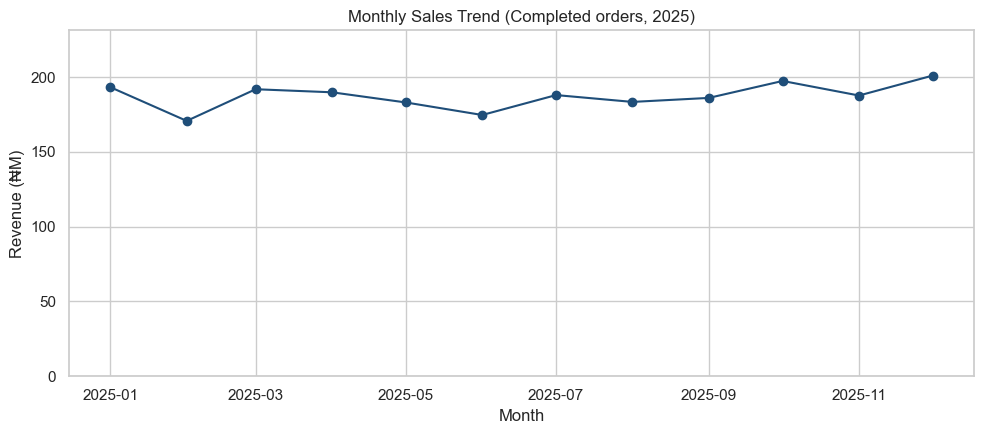

Takeaway: peak month December (₦201M), lowest February (₦171M); sales are fairly flat, no strong seasonality.


In [18]:
# 1. Monthly sales trend
monthly = done.groupby("month").revenue.sum() / M
plt.figure(figsize=(10,4.5)); plt.plot(monthly.index, monthly.values, marker="o", color="#1f4e79")
plt.title("Monthly Sales Trend (Completed orders, 2025)"); plt.xlabel("Month"); plt.ylabel("Revenue (₦M)")
plt.ylim(0, monthly.max()*1.15); save("01_monthly_sales_trend")
print(f"Takeaway: peak month {monthly.idxmax():%B} (₦{monthly.max():,.0f}M), lowest {monthly.idxmin():%B} (₦{monthly.min():,.0f}M); sales are fairly flat, no strong seasonality.")

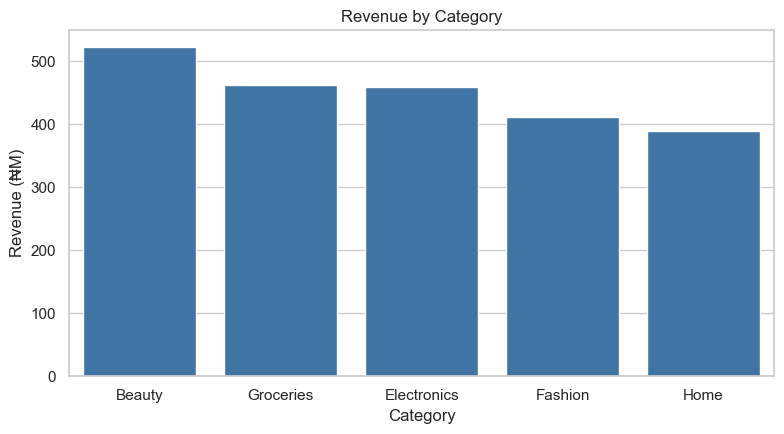

Takeaway: Beauty leads with ₦523M (23.3% of revenue); Home is lowest.


In [19]:
# 2. Revenue by category
cat = done.groupby("category").revenue.sum().sort_values(ascending=False) / M
plt.figure(figsize=(8,4.5)); sns.barplot(x=cat.index, y=cat.values, color="#2e75b6")
plt.title("Revenue by Category"); plt.xlabel("Category"); plt.ylabel("Revenue (₦M)"); save("02_revenue_by_category")
print(f"Takeaway: {cat.index[0]} leads with ₦{cat.iloc[0]:,.0f}M ({cat.iloc[0]/cat.sum():.1%} of revenue); {cat.index[-1]} is lowest.")

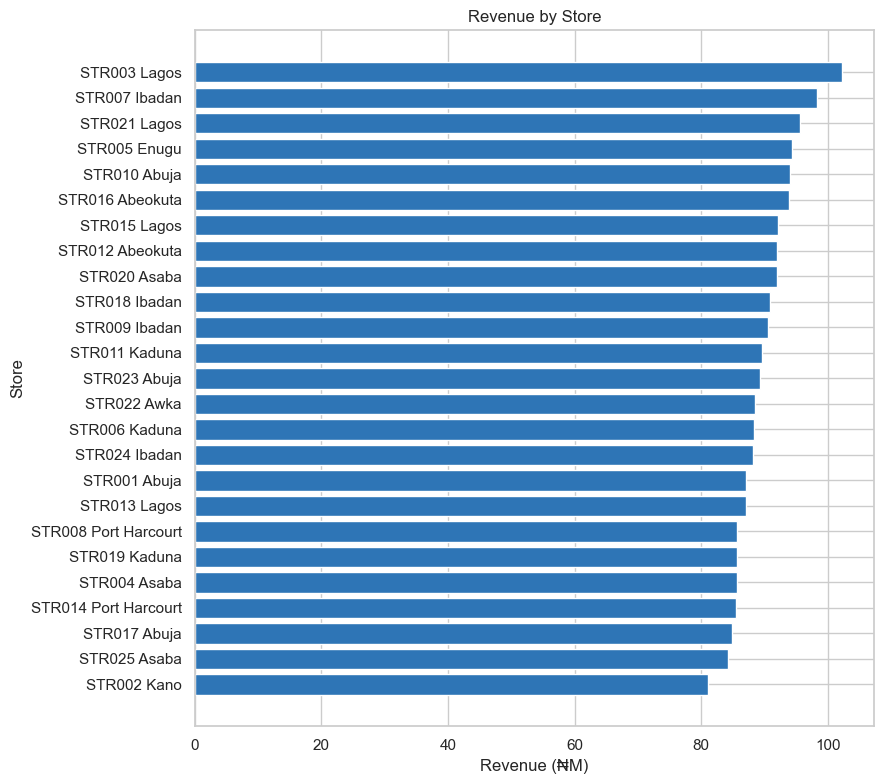

Takeaway: best store STR003 Lagos (₦102M), weakest STR002 Kano (₦81M).


In [20]:
# 3. Revenue by store (grouped by Store_ID because store names repeat)
st = done.groupby("store_id").revenue.sum().sort_values() / M
st.index = [store_label[i] for i in st.index]
plt.figure(figsize=(9,8)); plt.barh(st.index, st.values, color="#2e75b6")
plt.title("Revenue by Store"); plt.xlabel("Revenue (₦M)"); plt.ylabel("Store"); save("03_revenue_by_store")
print(f"Takeaway: best store {st.index[-1]} (₦{st.iloc[-1]:,.0f}M), weakest {st.index[0]} (₦{st.iloc[0]:,.0f}M).")

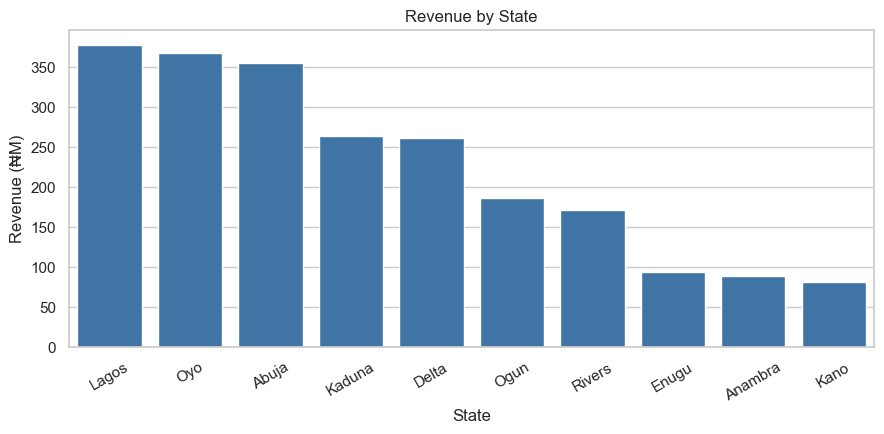

Takeaway: Lagos is the top state (₦377M) but it also has the most stores; see per-store comparison in Q9.


In [21]:
# 4. Revenue by state (store state)
stt = done.groupby("store_state").revenue.sum().sort_values(ascending=False) / M
plt.figure(figsize=(9,4.5)); sns.barplot(x=stt.index, y=stt.values, color="#2e75b6")
plt.title("Revenue by State"); plt.xlabel("State"); plt.ylabel("Revenue (₦M)"); plt.xticks(rotation=30); save("04_revenue_by_state")
print(f"Takeaway: {stt.index[0]} is the top state (₦{stt.iloc[0]:,.0f}M) but it also has the most stores; see per-store comparison in Q9.")

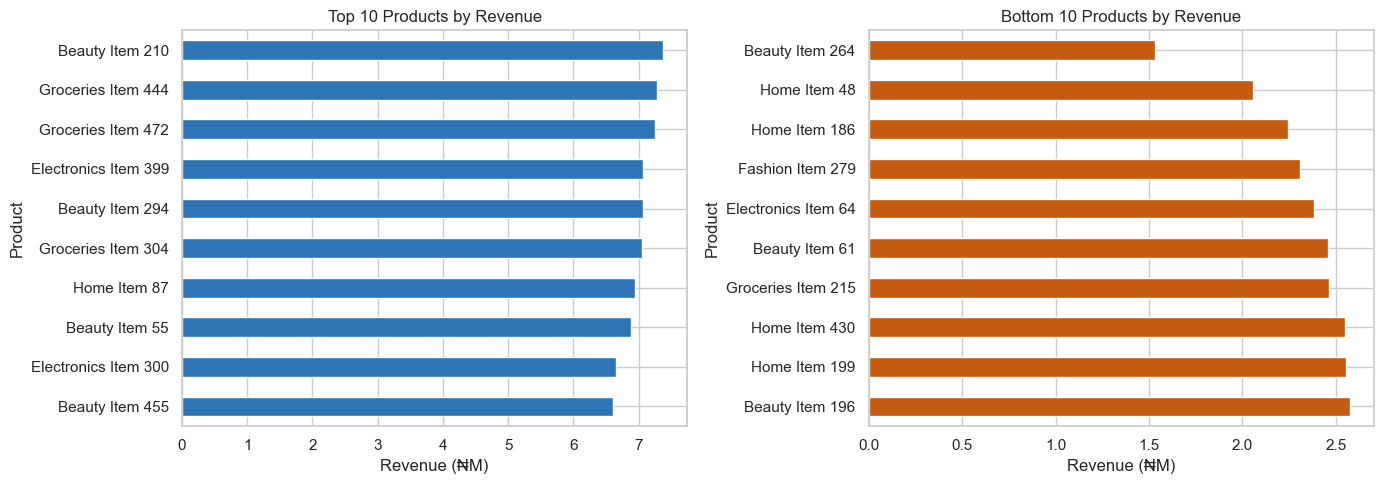

Takeaway: top product Beauty Item 210 (₦7.4M) earns 5x the weakest (Beauty Item 264); products with no Completed orders: 0.


In [22]:
# 5 & 6. Top 10 and Bottom 10 products by revenue
prod = done.groupby("product_name").revenue.sum().sort_values(ascending=False) / M
fig, ax = plt.subplots(1, 2, figsize=(14,5))
prod.head(10).sort_values().plot.barh(ax=ax[0], color="#2e75b6"); ax[0].set_title("Top 10 Products by Revenue"); ax[0].set_xlabel("Revenue (₦M)"); ax[0].set_ylabel("Product")
prod.tail(10).sort_values(ascending=False).plot.barh(ax=ax[1], color="#c55a11"); ax[1].set_title("Bottom 10 Products by Revenue"); ax[1].set_xlabel("Revenue (₦M)"); ax[1].set_ylabel("Product")
save("05_06_top_bottom_products")
print(f"Takeaway: top product {prod.index[0]} (₦{prod.iloc[0]:,.1f}M) earns {prod.iloc[0]/prod.iloc[-1]:,.0f}x the weakest ({prod.index[-1]}); products with no Completed orders: {500 - len(prod)}.")

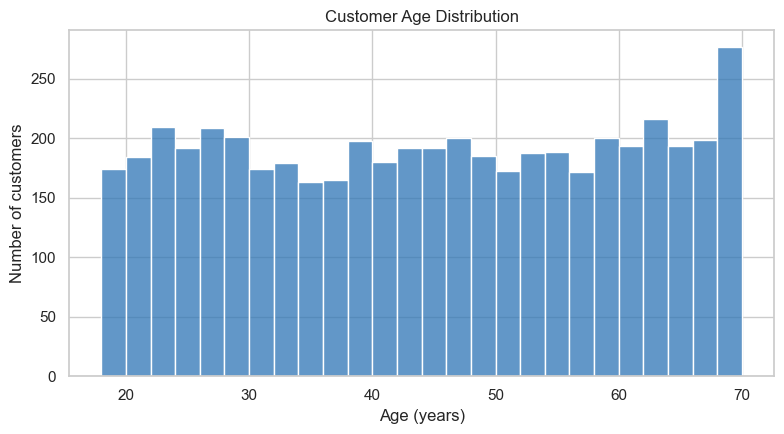

Takeaway: ages 18-70, median 44; spread evenly with no dominant age band.


In [23]:
# 7. Customer age distribution
plt.figure(figsize=(8,4.5)); sns.histplot(clean["customers"].age, bins=26, color="#2e75b6")
plt.title("Customer Age Distribution"); plt.xlabel("Age (years)"); plt.ylabel("Number of customers"); save("07_customer_age_distribution")
a = clean["customers"].age; print(f"Takeaway: ages {a.min()}-{a.max()}, median {a.median():.0f}; spread evenly with no dominant age band.")

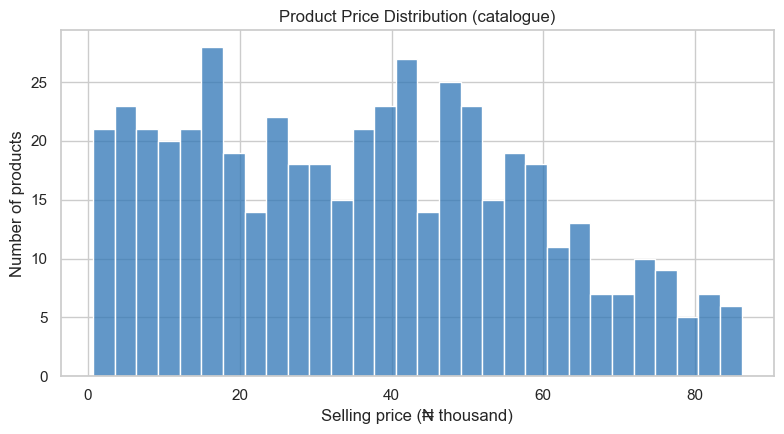

Takeaway: median price ₦35,771, range ₦676 to ₦86,153.


In [24]:
# 8. Product price distribution (catalogue selling price)
plt.figure(figsize=(8,4.5)); sns.histplot(clean["products"].selling_price/1000, bins=30, color="#2e75b6")
plt.title("Product Price Distribution (catalogue)"); plt.xlabel("Selling price (₦ thousand)"); plt.ylabel("Number of products"); save("08_product_price_distribution")
sp = clean["products"].selling_price; print(f"Takeaway: median price ₦{sp.median():,.0f}, range ₦{sp.min():,.0f} to ₦{sp.max():,.0f}.")

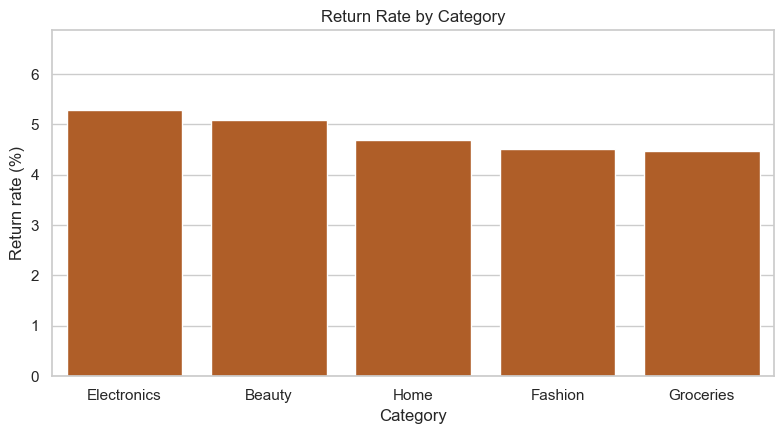

Takeaway: highest return rate Electronics (5.3%), lowest Groceries (4.5%); categories are close together.


In [25]:
# 9. Return rate by category (returns / Completed orders)
rr = done.groupby("category").is_returned.mean().sort_values(ascending=False) * 100
plt.figure(figsize=(8,4.5)); sns.barplot(x=rr.index, y=rr.values, color="#c55a11")
plt.title("Return Rate by Category"); plt.xlabel("Category"); plt.ylabel("Return rate (%)"); plt.ylim(0, rr.max()*1.3); save("09_return_rate_by_category")
print(f"Takeaway: highest return rate {rr.index[0]} ({rr.iloc[0]:.1f}%), lowest {rr.index[-1]} ({rr.iloc[-1]:.1f}%); categories are close together.")

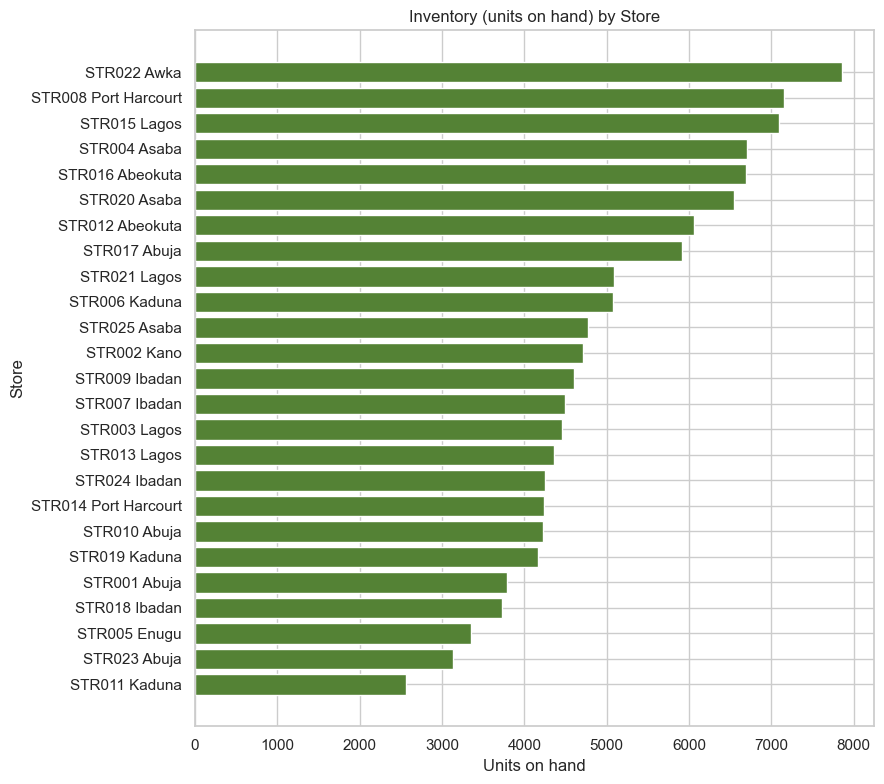

Takeaway: most stock STR022 Awka (7,853 units), least STR011 Kaduna (2,570 units). Note stores hold different numbers of product lines (9 to 27).


In [26]:
# 10. Inventory by store
invs = clean["inventory"].groupby("store_id").stock_on_hand.sum().sort_values()
invs.index = [store_label[i] for i in invs.index]
plt.figure(figsize=(9,8)); plt.barh(invs.index, invs.values, color="#548235")
plt.title("Inventory (units on hand) by Store"); plt.xlabel("Units on hand"); plt.ylabel("Store"); save("10_inventory_by_store")
print(f"Takeaway: most stock {invs.index[-1]} ({invs.iloc[-1]:,} units), least {invs.index[0]} ({invs.iloc[0]:,} units). Note stores hold different numbers of product lines (9 to 27).")

### 5b. Store staffing (Employees table)
The Employees table links to stores through `Store_ID`. Every store has exactly 5 employees, so headcount cannot explain revenue differences. Instead this section checks **role coverage** (does a store have a Store Manager?) and **average salary** against store revenue.

In [27]:
emp = clean["employees"].copy()
managers = emp.assign(is_mgr=emp.role.eq("Store Manager")).groupby("store_id").is_mgr.sum().rename("managers")
staff = (emp.groupby("store_id").agg(headcount=("employee_id","count"), avg_salary=("monthly_salary","mean"),
          monthly_payroll=("monthly_salary","sum")).join(managers).reset_index())
rev = done.groupby("store_id").revenue.sum().rename("revenue").reset_index()
staff = rev.merge(staff, on="store_id", how="left").merge(clean["stores"][["store_id","store_name","state"]], on="store_id")
staff["revenue_M"] = (staff.revenue / M).round(1)
print("Employees per store:", staff.headcount.value_counts().to_dict())
print("\nRole mix:"); display(emp.role.value_counts().to_frame("employees"))
print("Average monthly salary by role:"); display(emp.groupby("role").monthly_salary.mean().round(0).to_frame("avg_salary"))
print("\nStores with no Store Manager:", sorted(staff[staff.managers == 0].store_id))
by_mgr = staff.groupby("managers").agg(stores=("store_id","count"), avg_revenue_M=("revenue_M","mean")).round(1)
print("\nStore revenue by number of managers:"); display(by_mgr)
print("Correlation avg salary vs revenue:", round(staff[["avg_salary","revenue"]].corr().iloc[0,1], 3))

Employees per store: {5: 25}

Role mix:


,employees
role,
Customer Service,28
Cashier,28
Inventory Officer,25
Sales Associate,24
Store Manager,20


Average monthly salary by role:


,avg_salary
role,
Cashier,3278.0
Customer Service,3212.0
Inventory Officer,3154.0
Sales Associate,3166.0
Store Manager,3119.0



Stores with no Store Manager: ['STR003', 'STR008', 'STR012', 'STR013', 'STR016', 'STR017', 'STR018', 'STR019', 'STR020']

Store revenue by number of managers:


,stores,avg_revenue_M
managers,,
0,9,90.5
1,12,89.1
2,4,90.9


Correlation avg salary vs revenue: -0.248


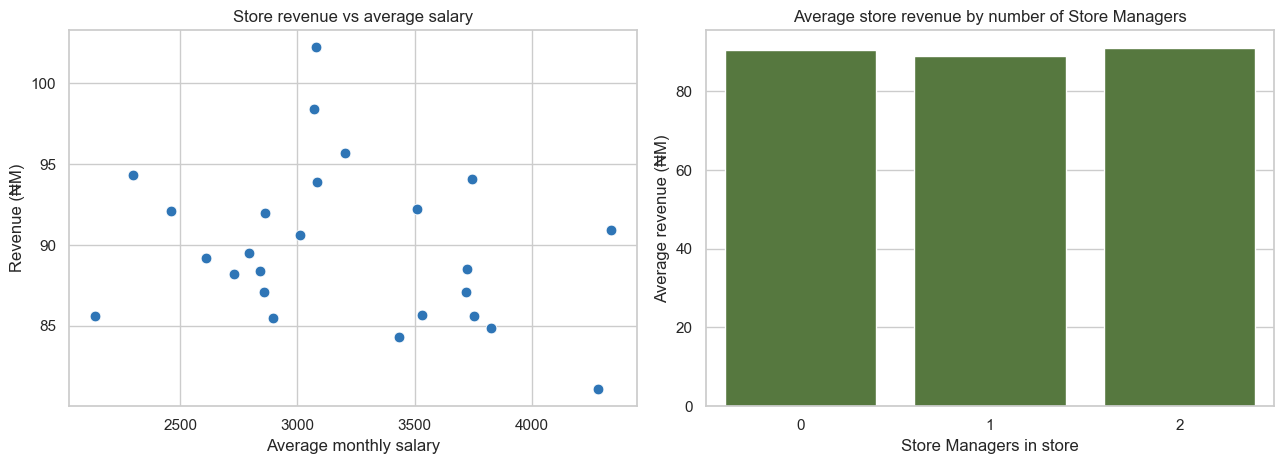

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=staff, x="avg_salary", y="revenue_M", ax=ax[0], s=60, color="#2e75b6")
ax[0].set_title("Store revenue vs average salary"); ax[0].set_xlabel("Average monthly salary"); ax[0].set_ylabel("Revenue (₦M)")
sns.barplot(data=staff, x="managers", y="revenue_M", ax=ax[1], color="#548235", errorbar=None)
ax[1].set_title("Average store revenue by number of Store Managers"); ax[1].set_xlabel("Store Managers in store"); ax[1].set_ylabel("Average revenue (₦M)")
save("14_staffing")
R_emp = {"total": int(len(emp)), "per_store": 5, "no_manager": int((staff.managers == 0).sum()),
         "corr_salary": round(staff[["avg_salary","revenue"]].corr().iloc[0,1], 3), "by_mgr": by_mgr.reset_index().values.tolist()}

## 6. Correlation analysis

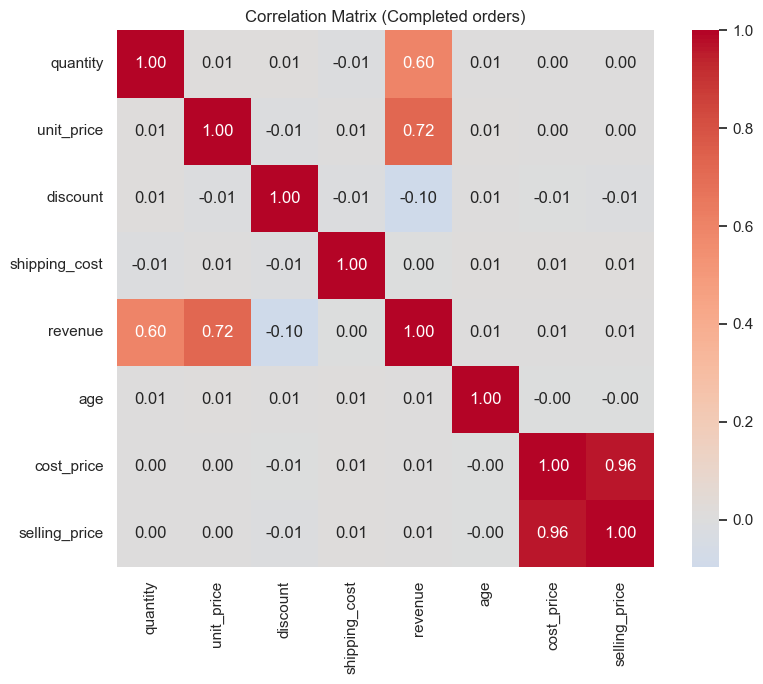

cost_price     selling_price    0.965
unit_price     revenue          0.720
quantity       revenue          0.600
discount       revenue         -0.098
shipping_cost  selling_price    0.012
discount       shipping_cost   -0.012


In [29]:
num_cols = ["quantity","unit_price","discount","shipping_cost","revenue","age","cost_price","selling_price"]
corr = done[num_cols].corr()
plt.figure(figsize=(9,7)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix (Completed orders)"); save("11_correlation_heatmap")
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(key=abs, ascending=False)
print(pairs.head(6).round(3).to_string())

c:\Users\HomePC\anaconda3\envs\learn-env\lib\site-packages\seaborn\axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


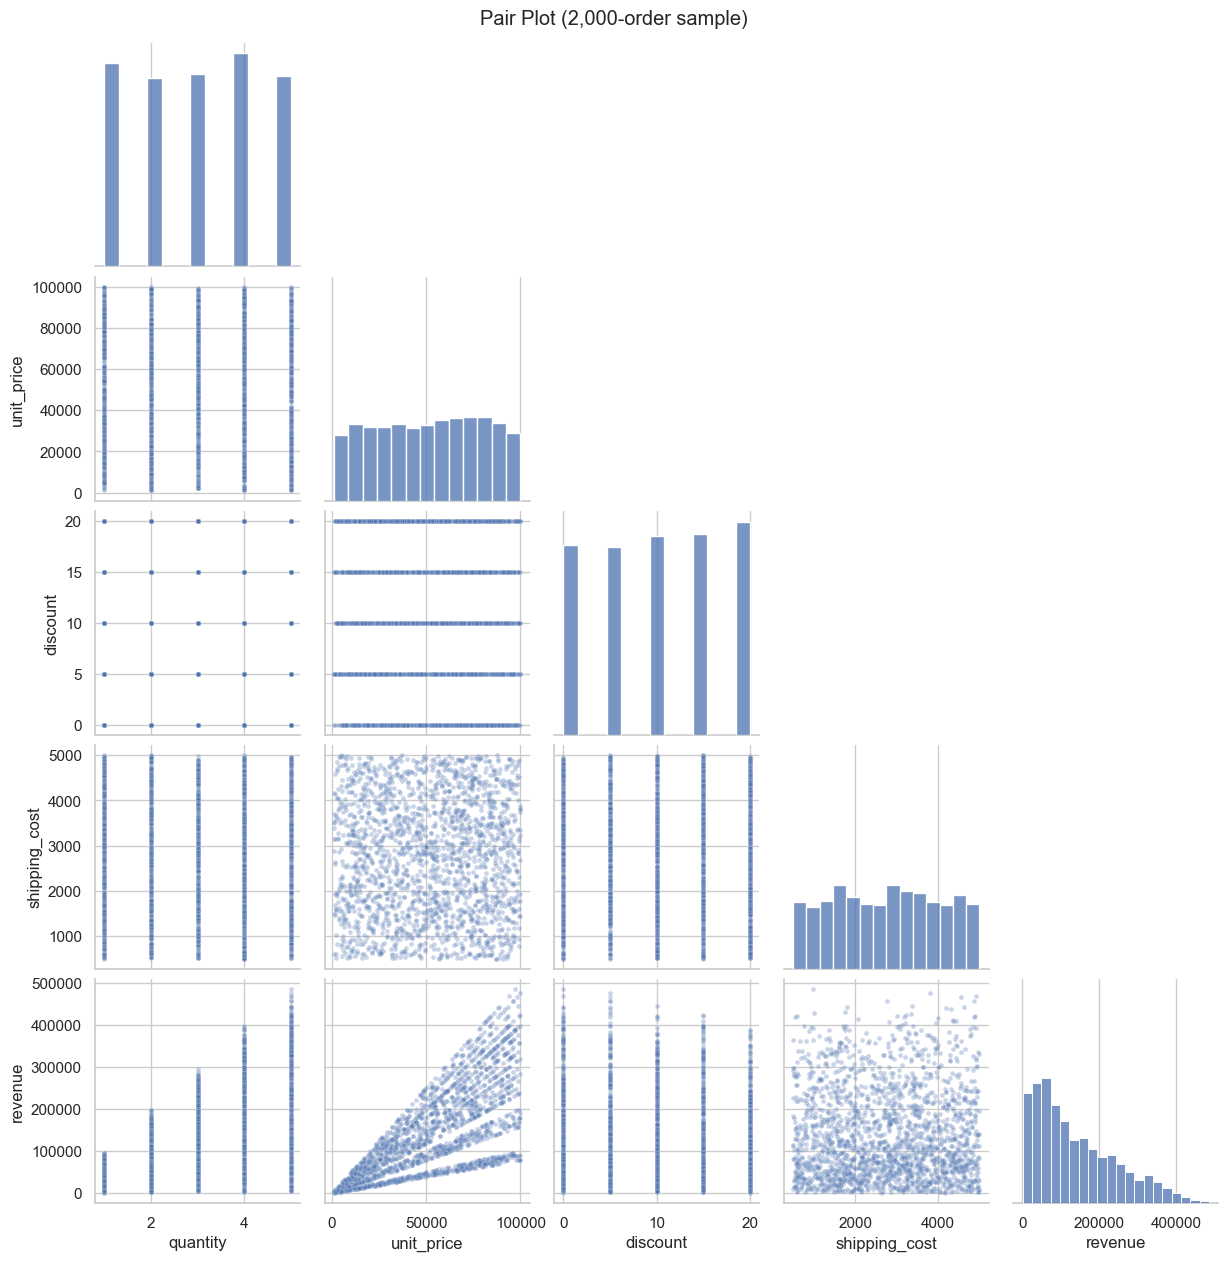

In [30]:
sample = done[["quantity","unit_price","discount","shipping_cost","revenue"]].sample(2000, random_state=42)
g = sns.pairplot(sample, corner=True, plot_kws={"alpha":0.3, "s":12}); g.figure.suptitle("Pair Plot (2,000-order sample)", y=1.01)
g.figure.savefig("Visualizations/12_pairplot.png", dpi=130, bbox_inches="tight"); plt.show()

**Interpretation:**
- **Strongly correlated:** `cost_price` and `selling_price` (0.97, cost is a share of price). `revenue` with `unit_price` (0.72) and `quantity` (0.60). The revenue links are mostly *by construction*, since revenue is calculated from price and quantity, so they are not independent discoveries.
- **Unrelated (about 0):** `age`, `shipping_cost` and `discount` show almost no relationship with anything else. Discount has a weak negative link with revenue (-0.10), and customer age does not predict spend.
- **Why it matters:** a model for order value will depend almost entirely on price and quantity. A model for returns will struggle because none of these fields explain return behaviour, so better predictors (customer history, delivery data, product attributes) need to be collected.

## 7. Feature engineering

In [31]:
fe = master.copy()
# Margin: transaction margin uses the order's own price; catalogue margin uses list price vs cost
net_unit = fe.unit_price * (1 - fe.discount / 100)
fe["txn_profit_margin"]   = (net_unit - fe.cost_price) / net_unit
fe["catalogue_margin"]    = (fe.selling_price - fe.cost_price) / fe.selling_price
fe["order_month"]   = fe.order_date.dt.month
fe["order_quarter"] = fe.order_date.dt.quarter
fe["age_group"]     = pd.cut(fe.age, bins=[17,25,35,45,55,70], labels=["18-25","26-35","36-45","46-55","56-70"])
fe["discount_pct"]  = fe.discount / 100          # share of price given away
fe["discount_amount"] = fe.gross_revenue - fe.revenue

# Customer-level features (Completed orders)
snapshot = master.order_date.max() + pd.Timedelta(days=1)
cust = (master[master.order_status == "Completed"].groupby("customer_id")
        .agg(clv_approx=("revenue","sum"), n_orders=("order_id","count"), avg_order_value=("revenue","mean"),
             last_purchase=("order_date","max"), returns=("is_returned","sum")).reset_index())
cust["days_since_last_purchase"] = (snapshot - cust.last_purchase).dt.days
fe = fe.merge(cust[["customer_id","clv_approx","days_since_last_purchase"]], on="customer_id", how="left")

# Inventory status: stock relative to reorder level
inv_f = clean["inventory"].copy()
inv_f["stock_ratio"] = inv_f.stock_on_hand / inv_f.reorder_level
inv_f["inventory_status"] = pd.cut(inv_f.stock_ratio, bins=[0,1,5,np.inf], labels=["Low","Medium","High"], right=False)

fe.to_csv("Cleaned_Data/features_orders.csv", index=False)
cust.to_csv("Cleaned_Data/features_customers.csv", index=False)
inv_f.to_csv("Cleaned_Data/features_inventory.csv", index=False)
print(inv_f.inventory_status.value_counts().to_string())
fe[["txn_profit_margin","catalogue_margin","order_month","order_quarter","age_group","discount_pct","clv_approx","days_since_last_purchase"]].describe(include="all").T

inventory_status
High      369
Medium    110
Low        21


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
txn_profit_margin,50000.0,NaN,NaN,NaN,-0.323511,3.034577,-53.163081,-0.090692,0.448154,0.731444,0.994539
catalogue_margin,50000.0,NaN,NaN,NaN,0.294602,0.098705,0.091384,0.217631,0.301485,0.385736,0.444266
order_month,50000.0,NaN,NaN,NaN,6.5337,3.453187,1.0,4.0,7.0,10.0,12.0
order_quarter,50000.0,NaN,NaN,NaN,2.5112,1.118043,1.0,2.0,3.0,4.0,4.0
age_group,50000,5,56-70,14378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
discount_pct,50000.0,NaN,NaN,NaN,0.099706,0.070863,0.0,0.05,0.1,0.15,0.2
clv_approx,48554.0,NaN,NaN,NaN,509272.519038,326985.77251,1590.0,257382.6,454462.55,696598.5,2022739.55
days_since_last_purchase,48554.0,NaN,NaN,NaN,89.524777,80.011655,1.0,28.0,66.0,129.0,364.0


| Feature | Why it may improve a future model |
|---|---|
| **Profit margin** | Separates high-volume from high-profit products; useful for pricing and promotion models. (Transaction margin is often negative because order prices do not follow catalogue prices, a data issue to raise with the client.) |
| **Order month / quarter** | Lets forecasting models capture seasonality and promotion calendars. |
| **Customer age group** | Turns raw age into stable segments, which helps tree models and makes segment-level insights readable. |
| **Customer lifetime value (approx.)** | Total spend per customer identifies high-value customers for retention and churn models. |
| **Discount percentage** | Measures price sensitivity and how much discount is needed to drive sales or returns. |
| **Days since last purchase** | Recency is the classic predictor of churn and re-purchase. |
| **Inventory status (Low/Medium/High)** | Turns stock and reorder level into an actionable flag for restocking and stock-out prediction. |

## 8. Business questions
Each answer below is backed by the table or chart in the cell above it. Numbers are computed live (Completed orders).

In [32]:
R = {}   # key results stored for the report
# Q1. Products with the highest revenue
q1 = (done.groupby(["product_id","product_name","category"]).revenue.sum().sort_values(ascending=False).head(10) / M).round(1)
R["q1"] = q1.reset_index().values.tolist(); q1.to_frame("Revenue (₦M)")

,,,Revenue (₦M)
product_id,product_name,category,
PROD0210,Beauty Item 210,Beauty,7.4
PROD0444,Groceries Item 444,Groceries,7.3
PROD0472,Groceries Item 472,Groceries,7.2
PROD0399,Electronics Item 399,Electronics,7.1
PROD0294,Beauty Item 294,Beauty,7.1
PROD0304,Groceries Item 304,Groceries,7.1
PROD0087,Home Item 87,Home,6.9
PROD0055,Beauty Item 55,Beauty,6.9
PROD0300,Electronics Item 300,Electronics,6.7


In [33]:
# Q2. Best performing stores
q2 = done.groupby(["store_id","store_name","store_state"]).agg(revenue=("revenue","sum"), orders=("order_id","count"), aov=("revenue","mean")).sort_values("revenue", ascending=False)
q2["revenue"] = (q2.revenue/M).round(1); q2["aov"] = q2.aov.round(0)
R["q2"] = q2.head(5).reset_index().values.tolist(); R["q2_bottom"] = q2.tail(3).reset_index().values.tolist(); q2.head(10)

,,,revenue,orders,aov
store_id,store_name,store_state,,,
STR003,ShopSmart Lagos,Lagos,102.2,715,142941.0
STR007,ShopSmart Ibadan,Oyo,98.4,668,147238.0
STR021,ShopSmart Lagos,Lagos,95.7,699,136896.0
STR005,ShopSmart Enugu,Enugu,94.3,681,138475.0
STR010,ShopSmart Abuja,Abuja,94.1,680,138315.0
STR016,ShopSmart Abeokuta,Ogun,93.9,685,137050.0
STR015,ShopSmart Lagos,Lagos,92.2,693,133057.0
STR012,ShopSmart Abeokuta,Ogun,92.1,662,139067.0
STR020,ShopSmart Asaba,Delta,92.0,629,146185.0


In [34]:
# Q3. Customer segments that spend the most (total and per-order)
for col in ["customer_segment","gender","age_group"]:
    d = done.assign(age_group=pd.cut(done.age, [17,25,35,45,55,70], labels=["18-25","26-35","36-45","46-55","56-70"]))
    t = d.groupby(col, observed=True).agg(total_revenue_M=("revenue", lambda s: s.sum()/M), avg_order_value=("revenue","mean"), customers=("customer_id","nunique")).round(1)
    print(f"\n--- by {col} ---"); display(t); R["q3_"+col] = t.reset_index().values.tolist()
top_cust = (done.groupby("customer_id").revenue.sum().sort_values(ascending=False).head(10) / M).round(2)
R["top_customers"] = top_cust.reset_index().values.tolist(); print("\nTop 10 customers (₦M):"); display(top_cust.to_frame("Revenue (₦M)"))


--- by customer_segment ---


,total_revenue_M,avg_order_value,customers
customer_segment,,,
Bronze,734.2,135979.8,1569
Gold,762.6,135429.8,1623
Silver,750.1,136402.5,1603



--- by gender ---


,total_revenue_M,avg_order_value,customers
gender,,,
Female,1074.3,135373.2,2344
Male,1172.5,136450.1,2451



--- by age_group ---


,total_revenue_M,avg_order_value,customers
age_group,,,
18-25,344.8,132824.9,730
26-35,416.6,136804.4,887
36-45,421.7,134203.5,896
46-55,425.0,138350.6,894
56-70,638.8,136665.5,1388



Top 10 customers (₦M):


,Revenue (₦M)
customer_id,
CUST03257,2.02
CUST01671,2.02
CUST03050,1.96
CUST02344,1.89
CUST02253,1.83
CUST01721,1.79
CUST04267,1.77
CUST01248,1.67
CUST04068,1.65


In [35]:
# Q4. Products with high return rates (min 20 Completed orders to avoid small-sample noise)
pr = done.groupby(["product_id","product_name","category"]).agg(orders=("order_id","count"), returns=("is_returned","sum")).reset_index()
pr["return_rate_%"] = (pr.returns / pr.orders * 100).round(1)
q4 = pr[pr.orders >= 20].sort_values("return_rate_%", ascending=False).head(10)
R["q4"] = q4[["product_name","category","orders","returns","return_rate_%"]].values.tolist()
# Why do customers return? And do channel / payment / discount matter?
reasons = clean["returns"].return_reason.value_counts(); R["reasons"] = reasons.to_dict()
display(q4); display(reasons.to_frame("returns"))

,product_id,product_name,category,orders,returns,return_rate_%
270,PROD0271,Beauty Item 271,Beauty,29,5,17.2
348,PROD0349,Fashion Item 349,Fashion,29,5,17.2
428,PROD0429,Beauty Item 429,Beauty,35,6,17.1
442,PROD0443,Beauty Item 443,Beauty,31,5,16.1
450,PROD0451,Home Item 451,Home,31,5,16.1
251,PROD0252,Groceries Item 252,Groceries,25,4,16.0
41,PROD0042,Home Item 42,Home,25,4,16.0
467,PROD0468,Electronics Item 468,Electronics,33,5,15.2
268,PROD0269,Beauty Item 269,Beauty,27,4,14.8
2,PROD0003,Electronics Item 3,Electronics,35,5,14.3


,returns
return_reason,
Late Delivery,635
Wrong Item,615
Customer Changed Mind,611
Damaged,581


In [36]:
# Q5. Peak sales months
q5 = (done.groupby(done.order_date.dt.strftime("%b")).revenue.sum() / M).round(1).reindex(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
R["q5"] = q5.to_dict(); R["q5_quarter"] = (done.groupby(done.order_date.dt.quarter).revenue.sum()/M).round(1).to_dict()
display(q5.sort_values(ascending=False).head(3).to_frame("Revenue (₦M)")); print("By quarter:", R["q5_quarter"])

,Revenue (₦M)
order_date,
Dec,201.0
Oct,197.4
Jan,193.2


By quarter: {1: 555.8, 2: 547.5, 3: 557.4, 4: 586.1}


In [37]:
# Q6. Which categories are growing? Compare H2 vs H1 and Q4 vs Q1 (only one year of data, so this is indicative)
cq = done.pivot_table(index="category", columns=done.order_date.dt.quarter, values="revenue", aggfunc="sum") / M
cq["H2_vs_H1_%"] = ((cq[3]+cq[4]) / (cq[1]+cq[2]) - 1) * 100
cq["Q4_vs_Q1_%"] = (cq[4] / cq[1] - 1) * 100
R["q6"] = cq.round(1).reset_index().values.tolist(); cq.round(1)

order_date,1,2,3,4,H2_vs_H1_%,Q4_vs_Q1_%
category,,,,,,
Beauty,129.7,126.2,127.6,139.6,4.4,7.6
Electronics,109.5,116.5,117.8,114.8,2.9,4.8
Fashion,102.0,97.9,100.1,112.2,6.2,10.0
Groceries,118.6,109.7,115.1,119.9,2.9,1.1
Home,95.9,97.1,96.9,99.6,1.8,3.8


In [38]:
# Q7. Supplier performance. Suppliers link to products through Brand (supplier name = brand + ' Supplies').
sp = (done.groupby("brand").agg(revenue=("revenue","sum"), orders=("order_id","count"), returns=("is_returned","sum"), products=("product_id","nunique")).reset_index()
      .merge(clean["suppliers"][["brand","supplier_id","supplier_name","country"]], on="brand"))
sp["return_rate_%"] = (sp.returns / sp.orders * 100).round(1); sp["revenue_M"] = (sp.revenue/M).round(1)
cat_cnt = clean["products"].groupby("brand").product_id.nunique().rename("catalogue_products")
sp = sp.merge(cat_cnt, on="brand")
print("Suppliers supplying the most catalogue products:"); display(sp.sort_values("catalogue_products", ascending=False)[["supplier_id","supplier_name","catalogue_products","revenue_M"]].head(5))
print("Top suppliers by revenue:"); display(sp.sort_values("revenue", ascending=False)[["supplier_id","supplier_name","country","revenue_M","return_rate_%"]].head(5))
R["sup_most_products"] = sp.sort_values("catalogue_products", ascending=False)[["supplier_name","catalogue_products"]].head(3).values.tolist()
R["sup_top_rev"] = sp.sort_values("revenue", ascending=False)[["supplier_name","revenue_M","return_rate_%"]].head(3).values.tolist()
print("Suppliers with >1 product:", (cat_cnt > 1).sum(), "of", len(cat_cnt), "(delivery-delay data is not available, so on-time performance cannot be measured)")

Suppliers supplying the most catalogue products:


,supplier_id,supplier_name,catalogue_products,revenue_M
256,SUP158,Martinez Ltd Supplies,2,9.2
133,SUP100,Garcia PLC Supplies,2,8.3
381,SUP194,Rosales PLC Supplies,2,7.5
106,SUP017,Dyer LLC Supplies,2,8.2
463,SUP222,Williams Group Supplies,2,9.4


Top suppliers by revenue:


,supplier_id,supplier_name,country,revenue_M,return_rate_%
420,SUP039,Thomas Ltd Supplies,USA,10.6,6.5
463,SUP222,Williams Group Supplies,Germany,9.4,5.8
256,SUP158,Martinez Ltd Supplies,USA,9.2,3.1
265,SUP206,Matthews and Sons Supplies,China,8.9,2.9
402,SUP375,Smith PLC Supplies,China,8.7,4.7


Suppliers with >1 product: 11 of 489 (delivery-delay data is not available, so on-time performance cannot be measured)


In [39]:
# Q8. Stores/products with low inventory (stock below reorder level)
low = inv_f[inv_f.inventory_status == "Low"].merge(clean["products"][["product_id","product_name","category"]], on="product_id").merge(clean["stores"][["store_id","store_name","state"]], on="store_id")
low["shortfall"] = low.reorder_level - low.stock_on_hand
low_by_store = low.groupby(["store_id","store_name","state"]).agg(low_lines=("product_id","count")).sort_values("low_lines", ascending=False)
R["low_total"] = len(low); R["low_by_store"] = low_by_store.head(5).reset_index().values.tolist()
R["low_worst"] = low.sort_values("shortfall", ascending=False)[["product_name","store_id","stock_on_hand","reorder_level"]].head(5).values.tolist()
display(low.sort_values("shortfall", ascending=False)[["store_id","store_name","product_name","stock_on_hand","reorder_level","shortfall"]].head(10)); display(low_by_store.head(5))

,store_id,store_name,product_name,stock_on_hand,reorder_level,shortfall
15,STR013,ShopSmart Lagos,Home Item 302,14,46,32
1,STR009,ShopSmart Ibadan,Home Item 414,13,44,31
6,STR014,ShopSmart Port Harcourt,Electronics Item 165,14,45,31
10,STR022,ShopSmart Awka,Home Item 212,12,41,29
8,STR021,ShopSmart Lagos,Electronics Item 146,21,47,26
16,STR018,ShopSmart Ibadan,Beauty Item 371,16,41,25
14,STR006,ShopSmart Kaduna,Home Item 478,28,50,22
20,STR017,ShopSmart Abuja,Beauty Item 479,10,29,19
4,STR001,ShopSmart Abuja,Fashion Item 272,16,29,13
2,STR002,ShopSmart Kano,Fashion Item 59,11,23,12


,,,low_lines
store_id,store_name,state,
STR006,ShopSmart Kaduna,Kaduna,3
STR014,ShopSmart Port Harcourt,Rivers,3
STR001,ShopSmart Abuja,Abuja,2
STR009,ShopSmart Ibadan,Oyo,2
STR018,ShopSmart Ibadan,Oyo,2


In [40]:
# Q9. Region and state performance. Stores per region differ, so compare revenue PER STORE as well as total.
reg = done.groupby("region").agg(revenue=("revenue","sum"), stores=("store_id","nunique"))
reg["revenue_M"] = (reg.revenue/M).round(1); reg["revenue_per_store_M"] = (reg.revenue/reg.stores/M).round(1)
stt = done.groupby("store_state").agg(revenue=("revenue","sum"), stores=("store_id","nunique"))
stt["revenue_M"] = (stt.revenue/M).round(1); stt["per_store_M"] = (stt.revenue/stt.stores/M).round(1)
R["q9_region"] = reg[["revenue_M","stores","revenue_per_store_M"]].reset_index().values.tolist()
R["q9_state"] = stt[["revenue_M","stores","per_store_M"]].sort_values("per_store_M", ascending=False).reset_index().values.tolist()
display(reg[["revenue_M","stores","revenue_per_store_M"]]); display(stt[["revenue_M","stores","per_store_M"]].sort_values("per_store_M", ascending=False))

,revenue_M,stores,revenue_per_store_M
region,,,
East,624.0,7,89.1
North,547.8,6,91.3
South,724.5,8,90.6
West,350.6,4,87.6


,revenue_M,stores,per_store_M
store_state,,,
Enugu,94.3,1,94.3
Lagos,377.2,4,94.3
Ogun,185.9,2,93.0
Oyo,368.0,4,92.0
Abuja,355.2,4,88.8
Anambra,88.5,1,88.5
Kaduna,263.5,3,87.8
Delta,261.8,3,87.3
Rivers,171.2,2,85.6


In [41]:
# Q10. Patterns that could support predictive modelling. Check what actually drives returns.
rate = lambda col: (done.groupby(col, observed=True).is_returned.mean()*100).round(2)
fe_done = fe[fe.order_status == "Completed"].copy()
fe_done["discount_band"] = pd.cut(fe_done.discount, [-1,5,10,15,20], labels=["0-5","6-10","11-15","16-20"])
for col in ["sales_channel","payment_method","customer_segment","gender"]: print(f"\nReturn rate % by {col}:\n", rate(col).to_string())
print("\nReturn rate % by discount band:\n", (fe_done.groupby("discount_band", observed=True).is_returned.mean()*100).round(2).to_string())
R["return_by_channel"] = rate("sales_channel").to_dict(); R["overall_return_rate"] = round(done.is_returned.mean()*100,2)


Return rate % by sales_channel:
 sales_channel
In-Store    5.04
Online      4.62

Return rate % by payment_method:
 payment_method
Card        4.86
Cash        4.79
Transfer    4.84

Return rate % by customer_segment:
 customer_segment
Bronze    4.87
Gold      5.04
Silver    4.56

Return rate % by gender:
 gender
Female    4.93
Male      4.74

Return rate % by discount band:
 discount_band
0-5      4.85
6-10     5.46
11-15    4.32
16-20    4.63


### Written answers to the business questions
*(Figures are Completed orders, revenue after discount, in ₦ millions. They match the tables above.)*

1. **Highest revenue product:** **Beauty Item 210 (PROD0210)** with ₦7.4M, followed by Groceries Item 444 (₦7.3M) and Groceries Item 472 (₦7.2M). Revenue is spread widely: the top product earns only about 0.3% of total revenue.
2. **Best store:** **STR003 ShopSmart Lagos** with ₦102.2M (715 orders), then STR007 Ibadan (₦98.4M) and STR021 Lagos (₦95.7M). The weakest is STR002 Kano (₦81.1M). Always group by Store_ID because store names repeat.
3. **Category that sells most:** **Beauty**, ₦523M (23.3% of revenue), ahead of Groceries (₦463M) and Electronics (₦459M). Home is lowest (₦390M).
4. **Highest-revenue month:** **December**, ₦201M, then October (₦197M) and January (₦193M). The lowest is February (₦171M). The spread is only about 17%, so there is no strong seasonality.
5. **Customers who spend most:** the top customers are CUST03257 and CUST01671 (about ₦2.02M each). Among segments, spend is nearly identical: Gold ₦763M, Silver ₦750M, Bronze ₦734M in total, with average orders about ₦135k to ₦136k in every group. Spend per order barely varies by gender or age either.
6. **Frequently returned products:** with at least 20 completed orders, the highest return rates are Fashion Item 349 and Beauty Item 271 (17.2% each), then Beauty Item 429 (17.1%). These rest on only 5 to 6 returns each, so treat them as watch-list items, not proof. The overall return rate is 4.83%. By category, Electronics is highest (5.3%) and Groceries lowest (4.5%). Reasons are evenly split: Late Delivery, Wrong Item, Customer Changed Mind and Damaged.
7. **Supplier with most products:** only 11 of 489 suppliers supply more than one product, and the most any supplies is 2 (for example Matthews and Sons Supplies, Rosales PLC Supplies and Smith PLC Supplies). Top supplier by revenue is Thomas Ltd Supplies (₦10.6M, 6.5% return rate). Delivery delays cannot be assessed because there is no delivery-date field.
8. **Low inventory:** **21 of 500** product-store lines are below their reorder level. STR006 Kaduna and STR014 Port Harcourt have the most (3 each). The largest shortfalls are Home Item 302 at STR013 (14 units vs reorder level 46) and Electronics Item 165 at STR014 (14 vs 45).
9. **Best region:** by total, **South** (₦724.5M, 8 stores). Per store, the regions are almost equal (North ₦91.3M, South ₦90.6M, East ₦89.1M, West ₦87.6M), so the South lead is mostly because it has more stores. By state per store, Lagos and Enugu lead (₦94.3M) and Kano is weakest (₦81.1M). Region labels conflict with State, so use State.
10. **Category to invest in:** **Beauty**. It leads revenue, grew about 4.4% in H2 vs H1, and Fashion grew fastest (about 6.2% H2 vs H1, +10% Q4 vs Q1) from a smaller base. Home has the lowest revenue and slowest growth. Only one year of data is available, so growth is indicative.

11. **Staffing (Employees table):** every store has exactly 5 employees (125 in total), so headcount does not explain revenue differences. **9 of 25 stores have no Store Manager** (including the top store, STR003) and 4 stores have two. Average store revenue is almost the same either way (₦90.5M with no manager, ₦89.1M with one, ₦90.9M with two), and average salary has only a weak negative link to revenue (-0.25 across 25 stores). Role assignment in the HR data should be checked.

**Patterns for predictive modelling:** return rates are flat across channel (In-Store 5.0% vs Online 4.6%), payment method, segment and discount band, so returns will be hard to predict from current fields. Better candidates are monthly sales forecasting, RFM customer segmentation, and inventory reorder prediction.

## 9. Bonus: customer segmentation with K-Means (RFM)

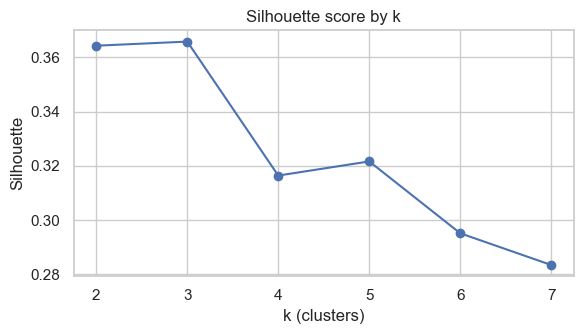

,customers,recency,frequency,monetary_M
segment,,,,
0,1660,62.15,4.14,0.57
1,957,234.26,1.97,0.25
2,1505,67.89,2.31,0.25
3,673,50.48,6.38,1.02


In [42]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

rfm = cust.rename(columns={"days_since_last_purchase":"recency","n_orders":"frequency","clv_approx":"monetary"})[["customer_id","recency","frequency","monetary"]]
X = StandardScaler().fit_transform(rfm[["recency","frequency","monetary"]])

scores = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=42).fit_predict(X)) for k in range(2, 8)}
plt.figure(figsize=(6,3.5)); plt.plot(list(scores), list(scores.values()), marker="o"); plt.title("Silhouette score by k"); plt.xlabel("k (clusters)"); plt.ylabel("Silhouette"); save("13_kmeans_silhouette")
K = 4
rfm["segment"] = KMeans(K, n_init=10, random_state=42).fit_predict(X)
profile = rfm.groupby("segment").agg(customers=("customer_id","count"), recency=("recency","mean"), frequency=("frequency","mean"), monetary_M=("monetary", lambda s: s.mean()/M)).round(2)
R["kmeans"] = profile.reset_index().values.tolist(); R["silhouette"] = {int(k): round(v,3) for k,v in scores.items()}
rfm.to_csv("Cleaned_Data/customer_segments_kmeans.csv", index=False); profile

**Approach:** RFM features (recency, frequency, monetary value) per customer from Completed orders, standardised, clustered with K-Means (k=4, chosen for interpretability; the silhouette plot shows how separable the clusters really are).

**Limitations:** the silhouette scores are low, meaning clusters are not sharply separated. The data covers only one year, and customers have few orders each. The dataset appears synthetic and evenly distributed, so real-world segments may differ. Use the clusters as a starting point, not a final segmentation.

In [43]:
import json
R["kpis"] = {k: float(v) for k, v in kpis.items()}
R["emp"] = R_emp
json.dump(R, open("Cleaned_Data/key_results.json", "w"), indent=1, default=str)
print("Saved key_results.json")

Saved key_results.json
